In [1]:
# # ---------------------------------------
# # Packages used across the whole analysis
# # ---------------------------------------

# # NumPy is the fundamental package for scientific computing in Python. It is a Python library that provides a multidimensional array object, various derived objects (such as masked arrays and matrices), and an assortment of routines for fast operations on arrays, including mathematical, logical, shape manipulation, sorting, selecting, I/O, discrete Fourier transforms, basic linear algebra, basic statistical operations, random simulation and much more.
import numpy as np
# import pandas as pd
# # A regular expression is a special sequence of characters that helps you match or find other strings or sets of strings, using a specialized syntax held in a pattern. Regular expressions are widely used in UNIX world.
# # The Python module re provides full support for Perl-like regular expressions in Python. The re module raises the exception re.error if an error occurs while compiling or using a regular expression.
import re
# # OpenCV-Python. Python is a general purpose programming language started by Guido van Rossum, which became very popular in short time mainly because of its simplicity and code readability. It enables the programmer to express his ideas in fewer lines of code without reducing any readability.
# # conda install -c conda-forge opencv
# # if it doesn't work use `pip install opencv-python`
import cv2 as cv
# # A module for dealing with the polylines used throughout Matplotlib. The primary class for polyline handling in Matplotlib is Path . Almost all vector drawing makes use of Path s somewhere in the drawing pipeline.
# import matplotlib.path as pa
# # Someone had the idea of combining both the PyPlot and NumPy namespaces into a single one (to avoid having to import two namespaces), the result is PyLab.
# import matplotlib.pylab as plt
# # The OS module in Python provides a way of using operating system dependent functionality. The functions that the OS module provides allows you to interface with the underlying operating system that Python is running on – be that Windows, Mac or Linux.
import os as os
# # Python time. time() The time() function returns the number of seconds passed since epoch. For Unix system, January 1, 1970, 00:00:00 at UTC is epoch (the point where time begins).
# import time as time
# # System-specific parameters and functions. This module provides access to some variables used or maintained by the interpreter and to functions that interact strongly with the interpreter. 
# import sys as sys
# # conda install -c conda-forge munkres
# # lowest costs algorithm
# import munkres

In [2]:
import matplotlib.pyplot as plt
# import matplotlib.image as mpimg

In [3]:
# Use to sort image file names
def _sort_nicely(l):
    """ Sort the given iterable in the way that humans expemt."""
    convert = lambda text: int(text) if text.isdigit() else text
    alphanum_key = lambda key: [convert(c)
                                for c in re.split('([0-9]+)',  key)]
    return sorted(l, key=alphanum_key)

# Detect components on a binarized image and return larger blobs only
def removeSmallBlobs(bwImg, bSize=10):
    """
    imgOut = removeSmallBlobs(bwImg, bSize) removes processes a binary image
    and removes the blobs which are smaller than bSize (area).
    """
    bwImg2 = np.uint8(bwImg.copy())
    bw = np.zeros(bwImg2.shape)

        #Find the contours,  count home many there are
    csl, _ = cv.findContours(bwImg2.copy(),
                                mode=cv.RETR_TREE,
                                method=cv.CHAIN_APPROX_SIMPLE)
    numC = int(len(csl))
    #Label each cell in the figure which are smaller than bSize
    for i in range(numC):
        area = cv.contourArea(csl[i])
        if area <= bSize:
            cv.drawContours(bw,  csl,  i,  1,  thickness=-1)
        else:
            cv.drawContours(bw,  csl,  i,  0,  thickness=-1)
    maskBW = 1-bw
    return np.uint8(bwImg2*maskBW)

# Find major and minor axis of a components moments (matrix)
def _findAxes(m):
    if m['m00']>0:
        """ Find the Minor and Major axis of an ellipse having moments m """
        Major = 2*(2*(((m['mu20'] + m['mu02']) +
                      ((m['mu20'] - m['mu02'])**2 +
                       4*m['mu11']**2)**0.5))/m['m00'])**0.5
        Minor = 2*(2*(((m['mu20'] + m['mu02']) -
                  ((m['mu20'] - m['mu02'])**2 +
                   4*m['mu11']**2)**0.5))/m['m00'])**0.5
    else:
        Major=1
        Minor=1
    return Major, Minor

# Remove small aspect ratio components from an image (input and output are images)
def removeSmallAspectRatio(bwImg, minaspectratio=4):
    """
    imgOut = removeSmallBlobs(bwImg, bSize) removes processes a binary image
    and removes the blobs which are smaller than bSize (area).
    """
    bwImg2 = np.uint8(bwImg.copy())
    bw = np.zeros(bwImg2.shape)

        #Find the contours,  count home many there are
    csl, _ = cv.findContours(bwImg2.copy(),
                                mode=cv.RETR_TREE,
                                method=cv.CHAIN_APPROX_SIMPLE)
    numC = int(len(csl))
    #Label each cell in the figure which are smaller than bSize
    for i in range(numC):
        if len(csl[i])>5:
            m = cv.moments(csl[i])
            #print(m)
            majorAxis, minorAxis = _findAxes(m)
            if majorAxis/minorAxis <= minaspectratio:
                cv.drawContours(bw,  csl,  i,  1,  thickness=-1)
            else:
                cv.drawContours(bw,  csl,  i,  0,  thickness=-1)
    maskBW = 1-bw
    return np.uint8(bwImg2*maskBW)

# Color coding
import seaborn as sns
huslcolor=sns.color_palette("husl", 180)
# Selection by position
import matplotlib.path as pa

# Detect components position and orientation, keep the components within the area define by 'polygon0' and color the components as a 
# function of their orientation
def colorImage(bwImg,polygon0=[[0,0],[0,1024],[1024,1024],[1024,0]]):
    """
    Returns first a colored image and second a binarized image
    """
    bwImg2 = np.uint8(bwImg.copy())
    bw0 = np.zeros(bwImg2.shape)
    bw = np.zeros(list(bwImg2.shape)+[3]) # Covert grayscale 0-255 to RGB (0-255,0-255,0-255)
    #bw2 = np.zeros(list(bwImg2.shape)+[3]) # Covert grayscale 0-255 to RGB (0-255,0-255,0-255)

    
        #Find the contours,  count home many there are
    csl, _ = cv.findContours(bwImg2.copy(),
                                mode=cv.RETR_TREE,
                                method=cv.CHAIN_APPROX_SIMPLE)
    numC = int(len(csl))
    #Label each cell in the figure which are smaller than bSize
    path = pa.Path(polygon0)
    for i in range(numC):
        if len(csl[i])>5:
            centroid, axes, angle = cv.fitEllipse(csl[i])
            isinside = path.contains_point(centroid)
            #print(colorsys.rgb_to_hsv(angle/180,angle/180,angle/180))
            if isinside==True:
                cv.drawContours(bw,  csl,  i,  color=np.array(huslcolor[int(angle)])*255,  thickness=-1)
                cv.drawContours(bw0,  csl,  i,  color=(255,255,255),  thickness=-1)

    return np.uint8(bw),np.uint8(bw0)

# Binarize image
def processImage2(imgIn, sBlur=0.5, sAmount=0, lnoise=1.5,
                 lobject=6, boxSize=13, smallblobsize0=120,
                distance0=40, normalize=True,fillhole=True,minaspectratio0=3):
    """
    Binarize image and remove small component/aspect ratio
    bwImg = processImage(imgIn, scaleFact = 1, sBlur = 0.5, sAmount = 0,
                         lnoise=1, lobject = 8, boxSize = 15,
                         solidThres = 0.65)
    returns a black and white image processed from
        a grayscale input (imgIn)
    sBlur = size of the characteristic noise you want
        to remove with a gaussian blur.
    sAmount = magnitude of the unsharp mask used to process the image
    lnoise = size of the typical noise when segmenting the image
    lobject = typical size of the pbject to be considered
    boxSize = size of the box used to compute the intensity threshold
        to start dividing (1.5 = 1.5 times the average length)
    """
    img = mat2gray(imgIn, 255)
    imgU = (unsharp(img, sBlur, sAmount))
    imgB = unsharp(bpass(imgU, lnoise, lobject).copy(), lnoise, 0)
    if normalize==True:
        imgB=imgB/np.max(imgB)*255
    bwImg = cv.adaptiveThreshold(np.uint8(imgB), 255,
                                 cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv.THRESH_BINARY, int(boxSize), 0)
    if fillhole==True:
        bwImg=fillholes(bwImg)
    bwImg = removeSmallBlobs(bwImg, smallblobsize0/2)
    bwImg = removeSmallAspectRatio(bwImg, minaspectratio=minaspectratio0)      
    return bwImg

# Filter image
def bpass(img, lnoise=1, lobject=8):
    """
    imgOut = bpass(img, lnoise, lobject) return an
    image filtered according to the lnoise (size of the noise)
    and the lobject (typical size of the object in the image) parameter.

    The script has been translated from the bpass.m script developed
    by John C. Crocker and David G. Grier."""

    from scipy import signal

    lnoise = np.double(lnoise)
    lobject = np.double(lobject)
    lobject= int(lobject)
    '(modification Louis 2/14/2020)'
    image_array = np.double(img)

    #Create the gaussian and boxcar kernels
    gauss_kernel = _anormalize(signal.gaussian(np.floor(10*lnoise) + 1,
                                               lnoise))
    boxcar_kernel = _anormalize(signal.boxcar(2*lobject))
    #Apply the filter to the input image
    gconv0 = cv.filter2D(np.transpose(image_array), -1, gauss_kernel)
    gconv = cv.filter2D(np.transpose(gconv0), -1, gauss_kernel)
    if lobject > 0:
        bconv0 = cv.filter2D(np.transpose(image_array), -1, boxcar_kernel)
        bconv = cv.filter2D(np.transpose(bconv0), -1, boxcar_kernel)
        #Create the filtered image
        filtered = gconv - bconv
        #Remove the values lower than zero
        filtered[filtered < 0] = 0
        #Output the final image
    else:
        filtered = gconv.copy()
    imgOut = filtered.copy()
    return imgOut


def mat2gray(img, scale=1):
    """
    imgOut = mat2gray(img, scale) return a rescaled matrix from 1 to scale
    """
    imgM = img - img.min()

    imgOut = imgM*np.double(scale)/imgM.max()

    return imgOut


def unsharp(img, sigma=5, amount=10):
    """
    imgOut = unshapr(img, sigma=5, amount=10) create an unsharp
    operation on an image.
    If amount=0, create a simple gaussian blur with size sigma.
    """
    if sigma:
        img = np.double(img)
        #imgB=cv.GaussianBlur(img, (img.shape[0]-1, img.shape[1]-1), sigma)
        imgB = cv.GaussianBlur(img, (img.shape[0]-(img.shape[0]+1) % 2,
                               img.shape[1]-(img.shape[1]+1) % 2),
                               np.double(sigma))
        imgS = img*(1 + amount) + imgB*(-amount)
        if amount:
            return imgS
        else:
            return imgB
    else:
        return img
    
def _anormalize(x):
    """ Normalize an array """
    y = x/np.sum(x)
    return y

def fillholes(img):
    import scipy.ndimage as ndimage
    img=ndimage.binary_fill_holes(img).astype(int)
    return img

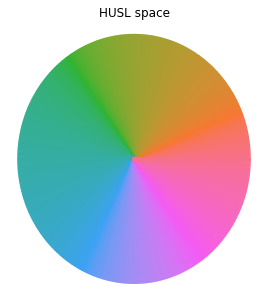

In [4]:
#
# Color space
#

from numpy import sin, cos, pi
import seaborn as sns

n = 314
theta = np.linspace(0, 2 * pi, n)

x = cos(theta)
y = sin(theta)

f = plt.figure(figsize=(10, 5))
with sns.color_palette("husl", n):
    ax = f.add_subplot(121)
    ax.plot([np.zeros_like(x), x], [np.zeros_like(y), y], lw=3)
    ax.set_axis_off()
    ax.set_title("HUSL space")

In [5]:
# Image file
WorkingDir=os.getcwd()
WorkingDir

'C:\\Users\\lbc77\\OneDrive - Cornell University\\Analysis\\Confinement\\PythonCode'

In [6]:
#
# - Import file list
#

# File path
fPath=WorkingDir

# List of files
tifList = []
# Get all files in folder
fileList = _sort_nicely(os.listdir(fPath))
# Select files that are lsm files
for f in fileList:
    if f.endswith('lsm'):
        tifList.append(f)

In [7]:
originalimagefile=WorkingDir+'\\'+tifList[0]
originalimagefile

'C:\\Users\\lbc77\\OneDrive - Cornell University\\Analysis\\Confinement\\PythonCode\\Image2.lsm'

C:\Users\lbc77\OneDrive - Cornell University\Analysis\Confinement\PythonCode\Image2.lsm


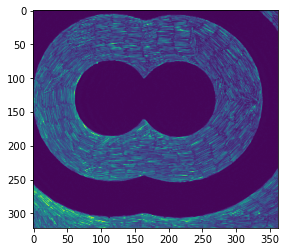

In [8]:
# figuresize=5
# ParamMinAspectRatio=4
# exportimage=True
#
# -- Show images
#
# Change 'center' and 'R' (bounding disk radius) to fit experiment
originalimage =cv.imread(originalimagefile, -1)
copy=originalimage.copy()
# Crop image
copy=copy[150:-40,50:-100]
print(originalimagefile)
plt.imshow(copy)

Original Dimensions :  (322, 362)
Resized Dimensions :  (1288, 1448)


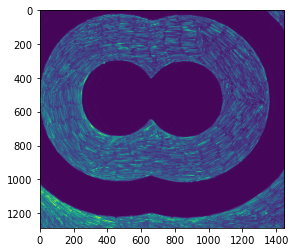

In [9]:
# Resize image

img = copy
 
print('Original Dimensions : ',img.shape)
scale_percent = 400 # percent of original size
width = int(img.shape[1] * scale_percent / 100)
height = int(img.shape[0] * scale_percent / 100)
dim = (width, height)
  
# resize image
resized = cv.resize(img, dim, interpolation = cv.INTER_AREA)
 
print('Resized Dimensions : ',resized.shape)
 
cv.imshow("Resized image", resized)
# cv2.waitKey(0)
# cv2.destroyAllWindows()
plt.imshow(resized)

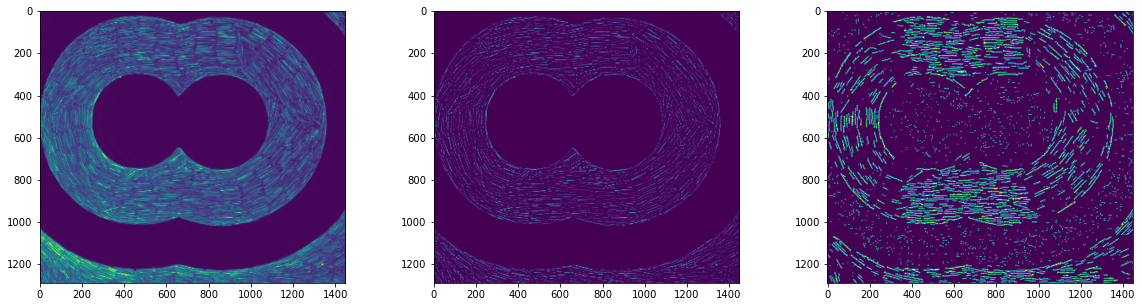

In [11]:
# Minimum aspect ratio
ParamMinAspectRatio=6

plt.figure(figsize = (20,5))

plt.subplot(131)
plt.imshow(resized)
plt.subplot(132)

sBlur0=1
lnoise0=0.5
lobject0=7
boxSize0=15

img = mat2gray(resized, 255)
imgU = (unsharp(img, sBlur0, 0))
imgB = unsharp(bpass(imgU, lnoise0, lobject0).copy(), lnoise0, 0)
plt.imshow(imgB)

plt.subplot(133)



bwImg = processImage2(resized, sBlur=sBlur0, sAmount=0,
                                     lnoise=lnoise0, lobject=lobject0,
                                      boxSize=np.double(boxSize0), smallblobsize0=10,minaspectratio0=ParamMinAspectRatio)
plt.imshow(bwImg)

In [12]:
tifList[0][:-4]

'Image2'

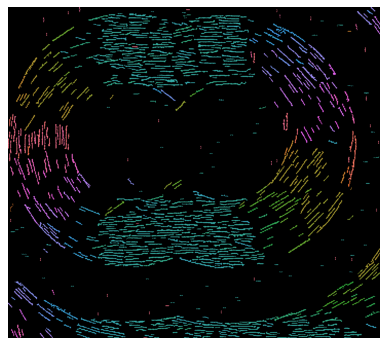

In [14]:
figuresize=6
exportimage=True
polygon0=[[0,0],[0,2000],[2000,2000],[2000,0]]
ci,bi=colorImage(bwImg,polygon0)
plt.figure(figsize=(figuresize, figuresize), dpi= 80, facecolor='w', edgecolor='k')
plt.axis('off')
plt.imshow(ci)
if exportimage==True:
    plt.savefig(tifList[0][:-4]+'_colorcrop'+'.pdf',bbox_inches='tight', pad_inches=0)  
# plt.close()

In [15]:
def regionprops(bwImage, scaleFact=1):
    """Replicate MATLAB's regionprops script.
    STATS = regionprops(bwImage, scaleFact=1) returns the following
    properties in the STATS array:
    STATS=[xPosition, yPosition, MajorAxis,
           MinorAxis, Orientation, Area, Solidity,
           BelongingpixelX,BelongingpixelY]
    """
    #import the relevant modules
    #Find the contours
    bwI = np.uint8(bwImage.copy())
    csr, _ = cv.findContours(bwI.copy(),
                                mode=cv.RETR_TREE,
                                method=cv.CHAIN_APPROX_SIMPLE)
    numC = int(len(csr))
    #Initialize the variables
    k = 0
    for i in range(numC):
        if len(csr[i]) >= 5:
            k += 1
    majorAxis = np.zeros((k, 1), dtype=float)
    minorAxis = np.zeros((k, 1), dtype=float)
    Orientation = np.zeros((k, 1), dtype=float)
    EllipseCentreX = np.zeros((k, 1), dtype=float)
    EllipseCentreY = np.zeros((k, 1), dtype=float)
    Area = np.zeros((k, 1), dtype=float)
    Solidity = np.zeros((k, 1), dtype=float)
    k = 0
    for i in range(numC):
        if len(csr[i]) >= 5:
            #Orientation
            centroid, axes, angle = cv.fitEllipse(csr[i])
            Orientation[k] = angle
            #Major, Minor axes
            #Centroid
            m = cv.moments(csr[i])
            if m['m00'] > 0:
                centroid = (m['m10']/m['m00'],
                            m['m01']/m['m00'])
                majorAxis[k], minorAxis[k] = _findAxes(m)
                EllipseCentreX[k] = centroid[0]
                EllipseCentreY[k] = centroid[1]
                #Solidity&Area
                Area[k] = m['m00']
                # CONVEX HULL stuff
                # convex hull vertices
                ConvexHull = cv.convexHull(csr[i])
                ConvexArea = cv.contourArea(ConvexHull)
                # Solidity : =  Area/ConvexArea
                Solidity[k] = np.divide(Area[k], ConvexArea)
            k += 1
    allData = np.zeros((k, 7))
    allData[:, 0] = EllipseCentreX.squeeze()/scaleFact
    allData[:, 1] = EllipseCentreY.squeeze()/scaleFact
    allData[:, 2] = majorAxis.squeeze()/scaleFact
    allData[:, 3] = minorAxis.squeeze()/scaleFact
    allData[:, 4] = Orientation.squeeze()
    allData[:, 5] = Area.squeeze()/scaleFact**2
    allData[:, 6] = Solidity.squeeze()
    return np.double(allData)

In [18]:
# Measure element properties and export
allres=regionprops(bwImg, scaleFact=1)
np.savetxt(WorkingDir+tifList[0]+'_X-Y-major-minor-Orient-Area-Solidity'+'.dat', allres)